In [1]:
%load_ext autoreload
%autoreload 2
import mcpp
import numpy as np
import pandas as pd


In [2]:
from mcpp.data_loader import DataSet, Patient

train_data = DataSet("training_data")


hello!
Loading patients
/Users/thartigan/Documents/Classes/ML/myocardia_prediction_project/data/training_data
['mixed_samples']
Unnamed: 0               0
MI                 healthy
age              62.593012
BMI              25.312186
height          161.647749
weight           64.949107
diastolic_BP      76.05767
systolic_BP     137.765801
sex                  False
Name: 0, dtype: object
Loading /Users/thartigan/Documents/Classes/ML/myocardia_prediction_project/data/training_data/mixed_samples/0healthy.npy
Unnamed: 0               1
MI                 healthy
age              58.037959
BMI              32.100795
height          172.543391
weight           94.715477
diastolic_BP     84.272113
systolic_BP     143.459426
sex                  False
Name: 1, dtype: object
Loading /Users/thartigan/Documents/Classes/ML/myocardia_prediction_project/data/training_data/mixed_samples/1healthy.npy
Unnamed: 0               2
MI                     pMI
age              65.840496
BMI              

In [3]:
display(train_data.train.data)

,Unnamed: 0,MI,age,BMI,height,weight,diastolic_BP,systolic_BP,sex
451,451,pMI,68.849725,26.674411,175.265079,81.579594,77.231258,141.035886,True
792,792,healthy,61.536688,24.548237,175.129347,75.356661,76.751299,131.074677,True
485,485,healthy,61.826583,25.437524,165.571592,68.667465,77.894261,137.513479,False
604,604,healthy,61.738111,24.729109,176.605977,77.384902,76.547294,130.424690,True
667,667,pMI,65.321546,31.876859,171.255231,92.343548,79.949368,143.013505,True
...,...,...,...,...,...,...,...,...,...
114,114,pMI,66.821823,31.160097,172.759490,92.152087,78.324178,139.805443,True
0,0,healthy,62.593012,25.312186,161.647749,64.949107,76.057670,137.765801,False
274,274,healthy,61.222239,29.408767,172.710242,87.404819,81.314557,137.701412,False
649,649,healthy,66.303166,24.483052,173.492392,74.109894,76.094680,137.782078,True



Anatomical labels:
Label 0.0: 6000 points
Label 1.0: 6000 points
Label 2.0: 6000 points


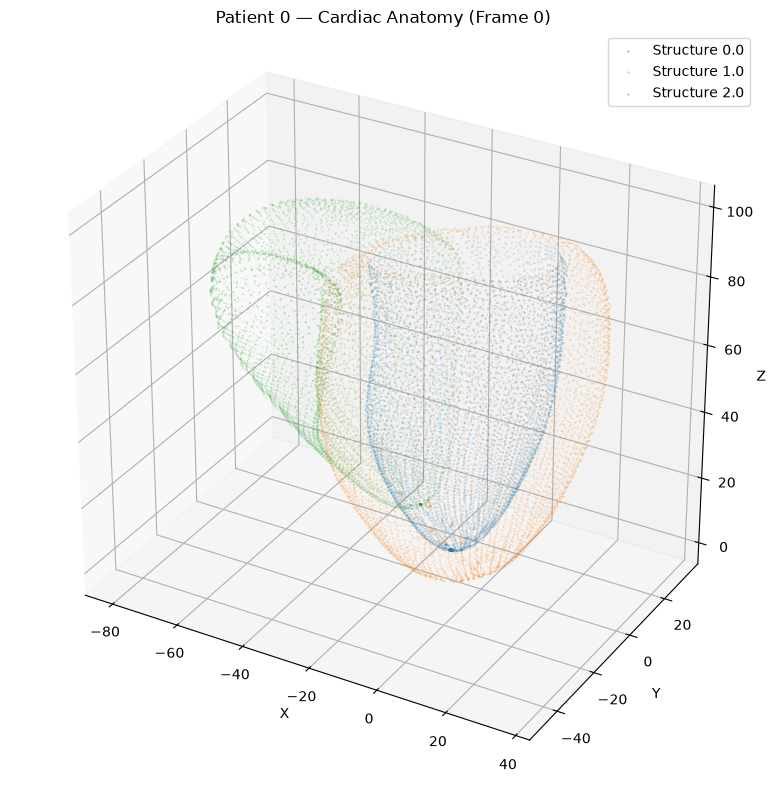


Anatomical labels:
Label 0.0: 6000 points
Label 1.0: 6000 points
Label 2.0: 6000 points


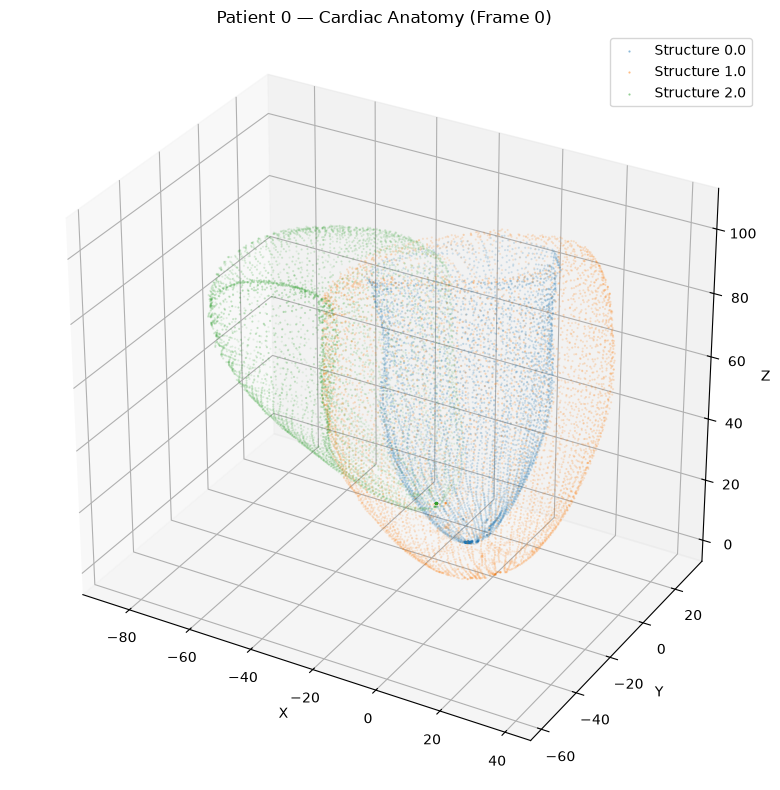

In [4]:
import mcpp.visualisation as vis
vis.visualise_cloud(train_data.train.patients[0], 0)
vis.visualise_cloud(train_data.val.patients[5], 0)

In [5]:
from mcpp.pca import pca_datasubset
pca_scores, model = pca_datasubset(train_data.train)
print(pca_scores)

[[-5.56744294e+02  1.86915187e+02 -1.07462725e+02 ...  9.02120031e-04
  -1.84102980e-04  5.30970797e-13]
 [-3.87238020e+02  4.10274821e+01  1.31058095e+02 ... -3.17052825e-03
  -1.67624366e-04  5.30970797e-13]
 [ 4.73169707e+02 -1.60986404e+02  2.34368691e+02 ...  5.91713701e-06
  -1.69635692e-07  5.30970797e-13]
 ...
 [ 2.45670143e+02  4.03720664e+02  2.11892064e+00 ... -4.02851922e-04
   1.58963818e-04  5.30970797e-13]
 [-5.75905245e+00 -3.44001262e+02  1.28779051e+02 ...  4.71987643e-04
  -8.27367227e-04  5.30970797e-13]
 [-3.35184445e+01  2.55156541e+02  2.16742893e+02 ... -1.94567146e-03
   1.25001323e-03  5.30970797e-13]]


In [6]:
pca = model[-1]
k = min(200, pca.n_components_)

display(pd.DataFrame({
    "component": np.arange(1, k + 1),
    "variance explained (%)": pca.explained_variance_ratio_[:k] * 100,
    "cumulative (%)": np.cumsum(pca.explained_variance_ratio_[:k]) * 100,
}))


,component,variance explained (%),cumulative (%)
0,1,31.075505,31.075505
1,2,19.940665,51.016170
2,3,11.404934,62.421104
3,4,4.601499,67.022603
4,5,3.826311,70.848914
...,...,...,...
195,196,0.000844,99.926636
196,197,0.000826,99.927462
197,198,0.000824,99.928286
198,199,0.000816,99.929101


In [7]:

display(pd.DataFrame(
    pca.components_[:, :30],
    index=[f"PC{i+1}" for i in range(pca.n_components_)],
    columns=[f"Feature {i+1}" for i in range(30)],
))


,Feature 1,Feature 2,Feature 3,Feature 4,Feature 5,Feature 6,Feature 7,Feature 8,Feature 9,Feature 10,...,Feature 21,Feature 22,Feature 23,Feature 24,Feature 25,Feature 26,Feature 27,Feature 28,Feature 29,Feature 30
PC1,-0.000080,-0.000022,-0.000134,-0.000089,0.000036,-0.000015,-0.000167,0.001393,0.001620,0.001449,...,0.001671,0.001110,3.315944e-16,0.001312,0.001662,0.001520,-8.771599e-16,0.001540,0.001444,0.001408
PC2,0.000284,0.000077,0.000257,0.000198,0.000053,0.000078,0.000258,-0.001433,-0.000049,0.000615,...,-0.000082,0.000714,-1.029633e-15,-0.001452,-0.000138,0.000388,1.383067e-15,-0.001266,-0.000109,0.000432
PC3,0.000236,-0.000262,0.000138,-0.000116,-0.000269,-0.000235,0.000309,0.001482,-0.001961,0.000593,...,-0.002046,0.000301,-7.715723e-16,0.001318,-0.002047,0.000658,7.409886e-16,0.001308,-0.002244,0.000483
PC4,-0.000331,-0.000226,-0.000220,-0.000301,0.000129,-0.000093,-0.000435,-0.000666,-0.001757,0.002778,...,-0.001445,0.002090,-1.457144e-15,-0.000732,-0.001368,0.002882,4.306269e-16,0.000425,-0.002082,0.003226
PC5,-0.000292,-0.000088,-0.000030,-0.000126,-0.000059,-0.000047,-0.000016,0.000216,0.000043,0.000479,...,0.000471,-0.002561,-4.720810e-16,0.000327,0.000812,0.001130,-2.653521e-15,0.002325,-0.000095,0.000876
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PC536,0.209232,0.000867,0.055107,0.002793,0.034656,0.105138,0.044210,0.000018,-0.000160,0.000293,...,-0.000648,0.000455,2.878401e-13,-0.000111,-0.000526,0.000357,-9.077236e-16,-0.000319,-0.000617,0.000295
PC537,-0.053985,-0.087126,0.222454,0.021268,0.082521,-0.136037,0.210765,0.000589,-0.000459,-0.001110,...,-0.000968,-0.000687,-2.322537e-13,0.000681,-0.000680,-0.000248,6.157217e-13,0.000366,-0.000809,-0.000531
PC538,0.014932,-0.122163,-0.033583,0.002992,0.264519,-0.211485,-0.129889,0.000460,-0.001157,0.000174,...,-0.000861,-0.000284,-6.687981e-13,-0.000013,-0.000799,-0.000368,-8.665495e-13,0.000306,-0.000572,-0.000448
PC539,0.167474,0.047907,0.051531,0.097233,-0.110573,-0.069928,0.054567,-0.001645,0.000933,0.000741,...,0.001019,0.000016,-5.588869e-13,-0.001328,0.000132,0.000068,1.142751e-13,-0.000569,0.000616,0.000242


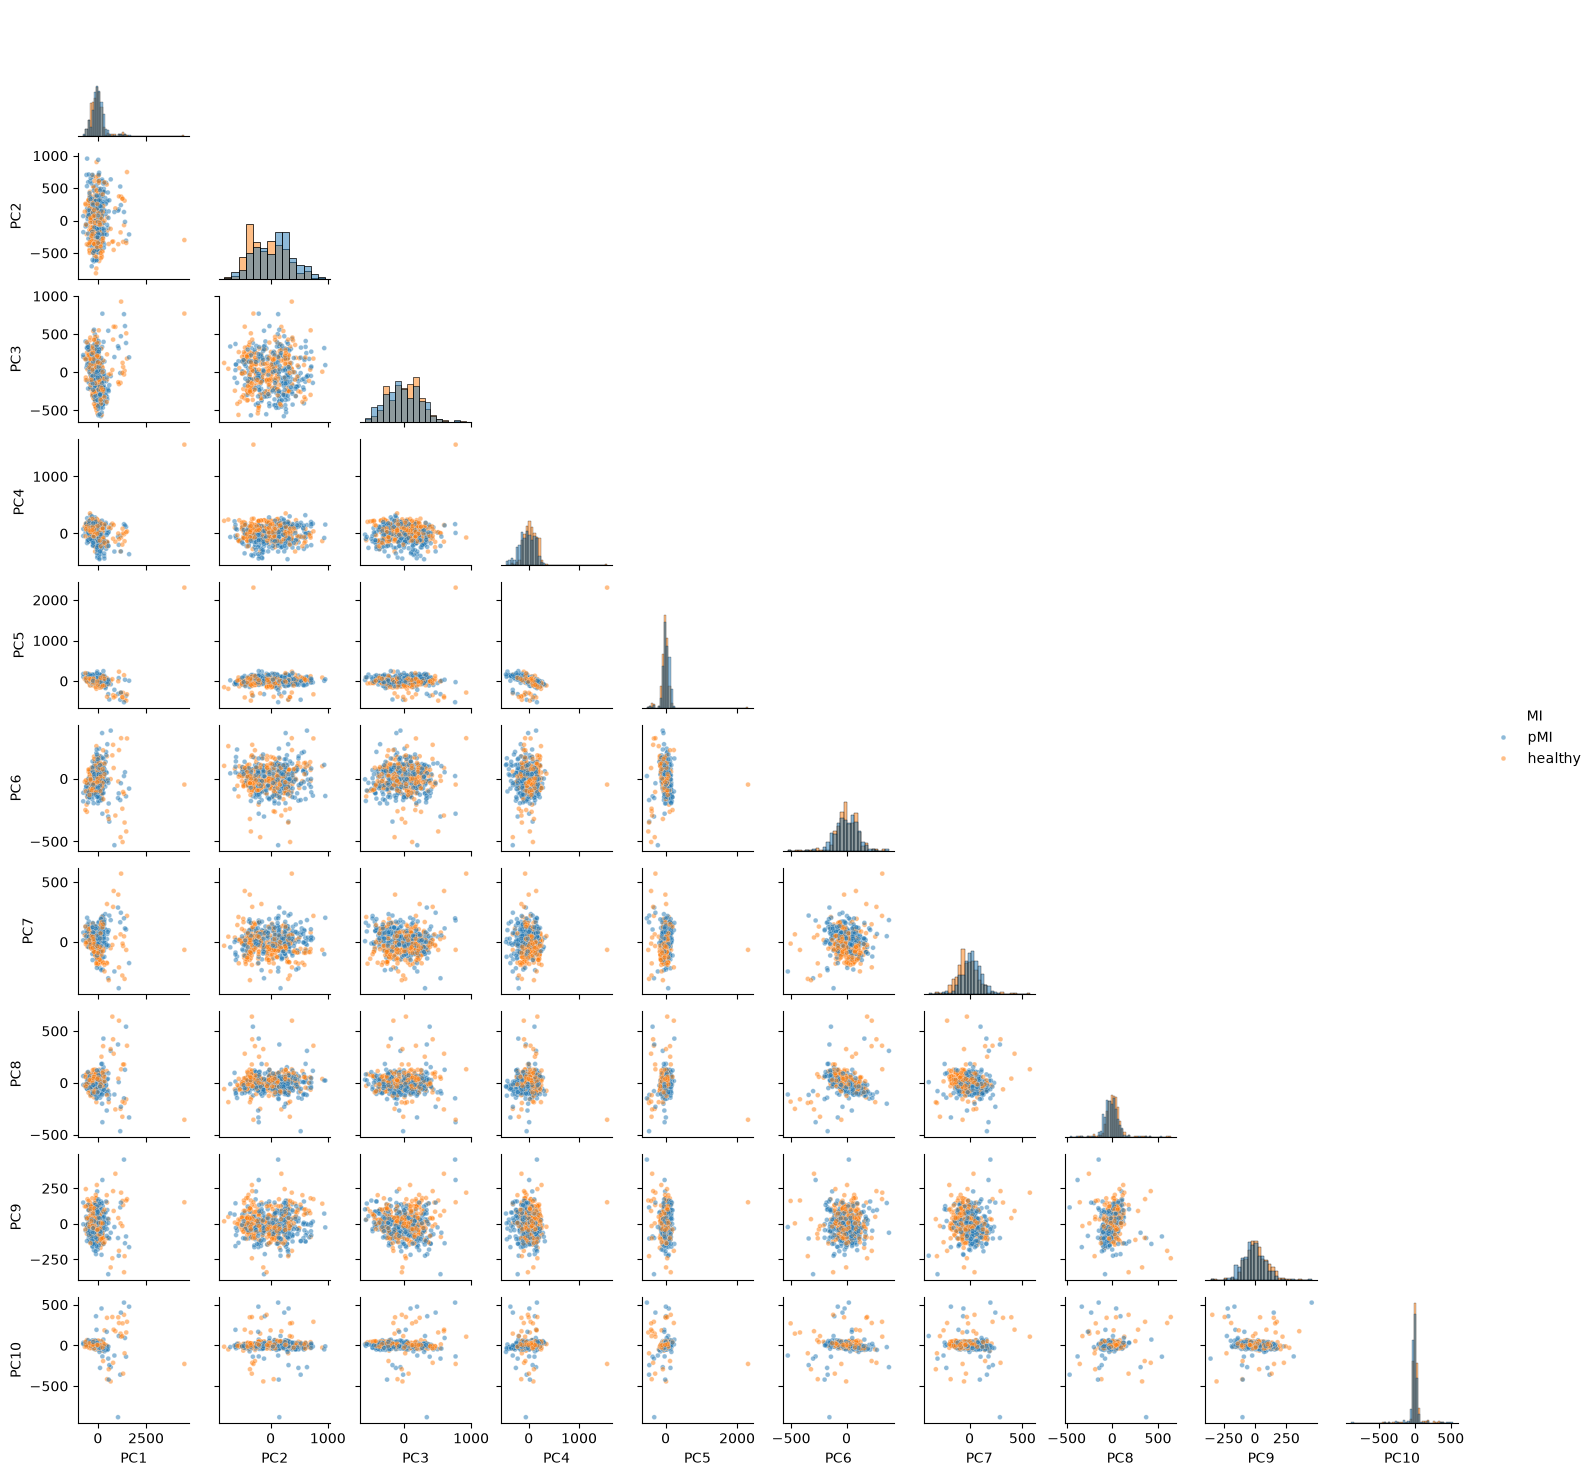

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

k = min(10, pca_scores.shape[1])
pc_columns = [f"PC{i+1}" for i in range(k)]

plot_data = pd.DataFrame(pca_scores[:, :k], columns=pc_columns)
plot_data["MI"] = train_data.train.data["MI"].to_numpy()

sns.pairplot(
    plot_data,
    vars=pc_columns,
    hue="MI",
    corner=True,
    diag_kind="hist",
    plot_kws={"s": 12, "alpha": 0.5},
    height=1.5,
)
plt.show()

In [9]:
display(train_data.train.patients[0].data)

array([[[-22.19453239,   6.65759325,   9.10894966,   2.        ],
        [-22.08612823,   6.75431681,   9.10576344,   2.        ],
        [-22.08703613,   6.72297049,   9.09356213,   2.        ],
        ...,
        [-19.88646126, -38.79456329,  49.36806107,   1.        ],
        [-18.64538765, -40.19440842,  53.23010254,   1.        ],
        [-17.94517136, -40.78277588,  54.71459198,   1.        ]],

       [[-20.87527847,   5.55369616,   9.25315094,   2.        ],
        [-20.80880165,   5.6483345 ,   9.25054169,   2.        ],
        [-20.7979908 ,   5.66328335,   9.24911976,   2.        ],
        ...,
        [-19.71401024, -37.09793091,  47.80887604,   1.        ],
        [-18.60546684, -38.3796196 ,  51.37761688,   1.        ],
        [-18.015522  , -38.87254333,  52.91772461,   1.        ]],

       [[-20.9516964 ,   4.7636528 ,   8.6530056 ,   2.        ],
        [-21.08605957,   4.61912632,   8.76046181,   2.        ],
        [-21.0912838 ,   4.58451223,   8.77465

In [10]:
n = min(200, len(pca_scores))
metadata = train_data.train.data.iloc[:n]

patient_pcs = pd.DataFrame(
    pca_scores[:n],
    index=metadata.index,
    columns=[f"PC{i+1} score" for i in range(pca_scores.shape[1])],
)
patient_pcs.index.name = "Patient index"
patient_pcs.insert(0, "MI", metadata["MI"].to_numpy())

with pd.option_context("display.max_rows", 200):
    display(patient_pcs)

,MI,PC1 score,PC2 score,PC3 score,PC4 score,PC5 score,PC6 score,PC7 score,PC8 score,PC9 score,...,PC531 score,PC532 score,PC533 score,PC534 score,PC535 score,PC536 score,PC537 score,PC538 score,PC539 score,PC540 score
Patient index,,,,,,,,,,,,,,,,,,,,,
451,pMI,-556.744294,186.915187,-107.462725,266.367892,-14.153884,-38.676003,17.559315,-56.686554,-8.943220,...,-0.009592,0.003266,-0.006314,0.005344,-0.005440,5.498636e-04,-0.004570,9.021200e-04,-1.841030e-04,5.309708e-13
792,healthy,-387.238020,41.027482,131.058095,-17.002239,68.652995,-20.317544,116.409221,-49.706868,-63.572318,...,-0.012223,0.008051,0.001552,0.005017,-0.006956,5.199740e-03,-0.004033,-3.170528e-03,-1.676244e-04,5.309708e-13
485,healthy,473.169707,-160.986404,234.368691,-145.794909,14.625068,178.607045,316.590728,-62.975526,149.671330,...,-0.000088,0.000032,-0.000021,-0.000057,-0.000036,1.587048e-05,-0.000011,5.917137e-06,-1.696357e-07,5.309708e-13
604,healthy,-443.118323,-143.564128,311.174263,-143.069146,125.729642,-7.610589,27.749275,-57.023687,-54.808777,...,0.018842,-0.010166,0.009204,-0.000268,-0.003984,3.643659e-03,-0.001891,-1.966586e-03,-1.275966e-04,5.309708e-13
667,pMI,-165.053346,-373.832523,-50.064286,-41.115680,31.964601,83.903575,-8.276494,-11.064640,40.810909,...,-0.006410,0.013414,-0.003191,-0.012009,-0.006082,-2.789675e-04,-0.000057,4.137084e-04,-6.291446e-04,5.309708e-13
803,pMI,-385.200117,606.401212,-125.621255,319.517525,-97.392343,58.801210,36.109660,-111.833276,-122.350791,...,-0.008558,0.000431,-0.000945,-0.000721,0.002349,7.181575e-04,-0.002140,2.651093e-04,-5.495062e-04,5.309708e-13
555,pMI,-47.592262,51.107443,68.703736,-4.888700,-16.816261,113.963285,-137.166465,-57.068016,-0.210701,...,-0.018320,-0.021288,0.000279,-0.006299,-0.003645,-2.582946e-03,0.000059,3.138937e-03,8.185343e-04,5.309708e-13
737,healthy,-234.687596,-23.925651,170.704188,-173.722852,125.266934,-59.442204,-48.436763,52.957412,60.360869,...,-0.050338,-0.025333,0.009606,0.006848,0.001080,-2.447003e-03,-0.000971,2.810638e-04,6.094589e-04,5.309708e-13
332,healthy,-97.408740,-462.018074,236.450900,-91.711495,6.802147,70.152119,-132.439951,21.126677,145.297763,...,0.008793,0.020477,0.016096,-0.020899,0.010993,-9.276657e-03,0.001264,1.271266e-03,-1.964101e-03,5.309708e-13


In [11]:
print(np.shape(train_data.train.patients[0].data))
print(train_data.train.patients[0])

(10, 18000, 4)


              precision    recall  f1-score   support

     healthy       0.80      0.92      0.86        91
         pMI       0.91      0.76      0.83        89

    accuracy                           0.84       180
   macro avg       0.85      0.84      0.84       180
weighted avg       0.85      0.84      0.84       180



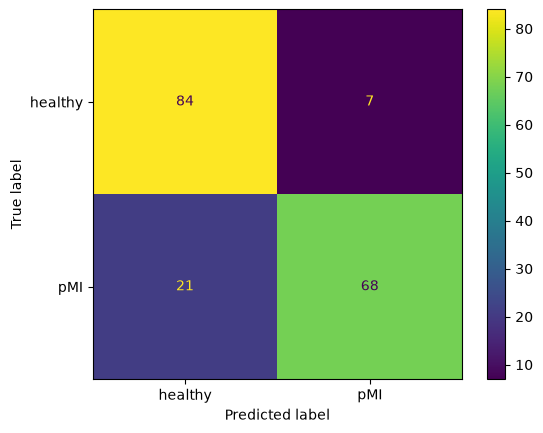

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Fit scaling and PCA on training patients only.
X_train, model_516 = pca_datasubset(train_data.train, n_components=540)
X_val, _ = pca_datasubset(train_data.val, model=model_516)

y_train = train_data.train.data["MI"].to_numpy()
y_val = train_data.val.data["MI"].to_numpy()

classifier = LogisticRegression(max_iter=20000)
classifier.fit(X_train, y_train)

predictions = classifier.predict(X_val)
print(classification_report(y_val, predictions))

from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_val, predictions)

              precision    recall  f1-score   support

     healthy       0.77      0.87      0.81        91
         pMI       0.84      0.73      0.78        89

    accuracy                           0.80       180
   macro avg       0.81      0.80      0.80       180
weighted avg       0.81      0.80      0.80       180



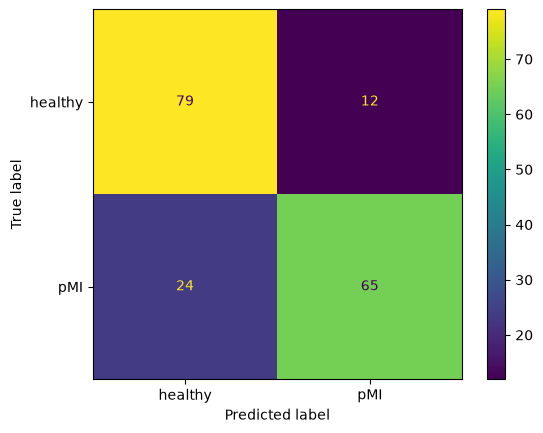

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Fit scaling and PCA on training patients only.
X_train, model_200 = pca_datasubset(train_data.train, n_components=200)
X_val, _ = pca_datasubset(train_data.val, model=model_200)

y_train = train_data.train.data["MI"].to_numpy()
y_val = train_data.val.data["MI"].to_numpy()

classifier = LogisticRegression(max_iter=20000)
classifier.fit(X_train, y_train)

predictions = classifier.predict(X_val)
print(classification_report(y_val, predictions))

from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_val, predictions)


In [14]:
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import classification_report

# print(len(train_data.train.data))

# # Fit scaling and PCA on training patients only.
# X_train, model_516 = pca_datasubset(train_data.train, n_components=1000)

# X_val, _ = pca_datasubset(train_data.val, model=1000)

# y_train = train_data.train.data["MI"].to_numpy()
# y_val = train_data.val.data["MI"].to_numpy()

# classifier = LogisticRegression(max_iter=20000)
# classifier.fit(X_train, y_train)

# predictions = classifier.predict(X_val)
# print(classification_report(y_val, predictions))

# from sklearn.metrics import ConfusionMatrixDisplay
# ConfusionMatrixDisplay.from_predictions(y_val, predictions)